# Assignment 1 — Working with Open Data

In this assignment you take a **real, public dataset**, ask questions of it, answer them, and document your work so that someone else could reproduce it.

**A few things to know before you start:**
- This course is about **data, not code.** The point of A1 is the analytical questions and what the numbers tell you about how people behave — *not* whether you remember Python syntax.
- You can do the analysis **in Python here, or in Google Sheets.** Every question below works either way. Pick whatever lets you think about the data instead of fighting the tool.
- You may use an **AI assistant** (ChatGPT, Claude, …) to help you write code — with rules. See *A note on using AI* at the bottom before you do.

**What you'll turn in** (committed to your `hcde-410` repo):
1. This notebook, with your answers filled in.
2. A short **README.md** describing your work.
3. A **LICENSE** file, and a note about the dataset's own license.

Your commit history is part of the record — commit as you go.

## Part 0 — Get the data

The data comes from [data.seattle.gov](https://data.seattle.gov/), the City of Seattle's open-data portal. We'll use the [Burke-Gilman Trail counter north of NE 70th St](https://data.seattle.gov/Transportation/Burke-Gilman-Trail-north-of-NE-70th-St-Bicycle-and/2z5v-ecg8), which records **bike and pedestrian traffic, by hour, by direction**.

We'll pull the data straight from the city's API rather than downloading a file by hand. That's a small reproducibility win: anyone who runs this notebook gets the same data the same way, and it's written down exactly where it came from.

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# The dataset's API endpoint, and a query for one year of data (2019).
# You can paste the full URL into a browser to preview the raw data.
api_endpoint = "https://data.seattle.gov/resource/2z5v-ecg8.json?"
api_parameters = "$limit=50000&$where=date > '2019-01-01T00:00:00' AND date < '2020-01-01T00:00:00'"

response = requests.get(api_endpoint + api_parameters)
raw_data = response.json()
print("Downloaded", len(raw_data), "hourly records.")
# If this cell fails (e.g. the API is down), see the note below the next cell.

Downloaded 8759 hourly records.


Now load it into a **pandas DataFrame** — a table, like a spreadsheet you can compute with.

In [3]:
df = pd.DataFrame(raw_data)
df.head()

,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south
0,2019-01-01T01:00:00.000,2,1,0,1,0
1,2019-01-01T02:00:00.000,1,0,0,0,1
2,2019-01-01T03:00:00.000,0,0,0,0,0
3,2019-01-01T04:00:00.000,1,0,0,1,0
4,2019-01-01T05:00:00.000,1,0,0,1,0


### Quick sanity checks

Whenever you work with data **you didn't create**, check that it means what you think before you analyze it. Two things need fixing here:
- the counts arrive as **text**, so we convert them to numbers;
- the `date` is a string, so we convert it to a real **datetime** and pull out the hour and weekday.

We'll also add tidy `bikes` and `peds` columns (north + south).

In [4]:
# convert the count columns from text to numbers
count_cols = ["bike_north", "bike_south", "ped_north", "ped_south", "bgt_north_of_ne_70th_total"]
df[count_cols] = df[count_cols].apply(pd.to_numeric, errors="coerce")

# convert the date string to a real datetime, and derive hour + weekday
df["date"] = pd.to_datetime(df["date"])
df["hour"] = df["date"].dt.hour
df["weekday"] = df["date"].dt.day_name()

# combined bike and pedestrian counts
df["bikes"] = df["bike_north"] + df["bike_south"]
df["peds"]  = df["ped_north"] + df["ped_south"]

df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8759 entries, 0 to 8758
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   date                        8759 non-null   datetime64[ns]
 1   bgt_north_of_ne_70th_total  8759 non-null   int64         
 2   ped_south                   8759 non-null   int64         
 3   ped_north                   8759 non-null   int64         
 4   bike_north                  8759 non-null   int64         
 5   bike_south                  8759 non-null   int64         
 6   hour                        8759 non-null   int32         
 7   weekday                     8759 non-null   object        
 8   bikes                       8759 non-null   int64         
 9   peds                        8759 non-null   int64         
dtypes: datetime64[ns](1), int32(1), int64(7), object(1)
memory usage: 650.2+ KB


,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south,hour,bikes,peds
count,8759,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000
mean,2019-07-02 12:00:00,58.423564,8.047380,8.363169,19.875671,22.137344,11.501313,42.013015,16.410549
min,2019-01-01 01:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2019-04-02 06:30:00,2.000000,0.000000,0.000000,0.000000,1.000000,6.000000,1.000000,0.000000
50%,2019-07-02 12:00:00,33.000000,5.000000,6.000000,9.000000,8.000000,12.000000,20.000000,11.000000
75%,2019-10-01 17:30:00,91.000000,13.000000,14.000000,31.000000,30.000000,17.500000,64.000000,27.000000
max,2019-12-31 23:00:00,1764.000000,1324.000000,782.000000,199.000000,961.000000,23.000000,1039.000000,1752.000000
std,NaN,73.656910,16.882468,13.164217,26.299728,34.080707,6.921886,56.534598,27.675776


**Look at what `describe()` tells you.** Are there hours with 0 traffic? Any missing values (a sensor can go offline)? Note anything odd — you'll want to mention data limitations later.

**No-code option:** run the next cell to save the cleaned data as a CSV, then open it in Google Sheets and do your analysis there. If you go this route, title your sheet **"A1 — [your name]"**, share it so anyone with the link can view, and paste the link into your written answers.

In [5]:
df.to_csv("bg_hourly_2019.csv", index=False)
print("Saved bg_hourly_2019.csv — a row per hour of 2019.")

Saved bg_hourly_2019.csv — a row per hour of 2019.


## Part 1 — One worked example: when do cyclists ride?

Here is the whole technique, **once**, so you can see the pattern. After this, the questions are yours.

The move is always the same: **group → summarize → plot → interpret.** In pandas that's a couple of lines (no loops needed).

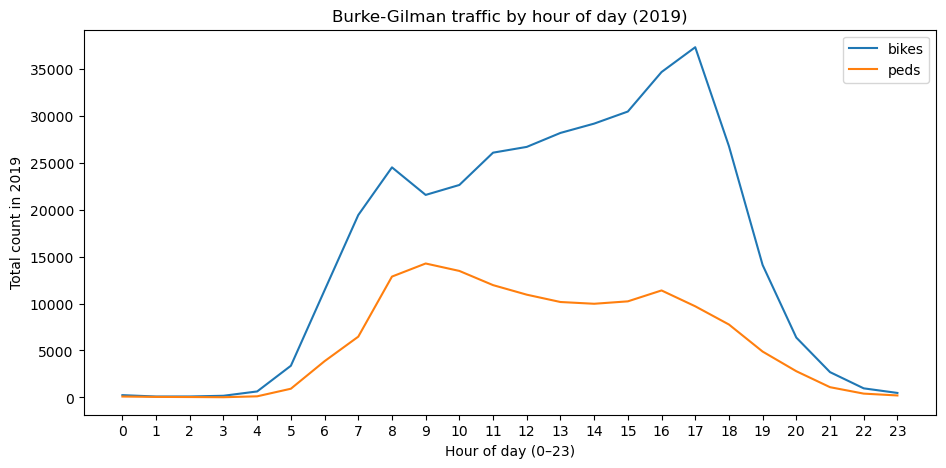

In [6]:
# group every row by its hour of day, and sum bikes and peds within each hour
by_hour = df.groupby("hour")[["bikes", "peds"]].sum()

by_hour.plot(figsize=(11, 5))
plt.title("Burke-Gilman traffic by hour of day (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))
plt.show()

**Now read the plot — this is the actual work.** What does the shape tell you? Do you see one peak or two? What might a double peak mean about *why* people are on the trail? That interpretation — turning a shape into a claim about human behavior — is what every question below is really asking for.

## Part 2 — Your analysis

Answer each question below. For every one:
1. **Show how you got there** — a pandas cell here, or (no-code) a link to your Google Sheet in the answer.
2. **Interpret it in 2–4 sentences** — what does this say about how people actually use the trail? The interpretation is the point, not the number.

There isn't a single right answer to most of these. Making a reasonable choice and *defending* it is the skill.

**Q1. When is the trail busiest, and when is it quietest?**
Decide what *busy* means to you first — a single hour? a stretch of the day? bikes and peds together, or separately? — and say why you chose that.

hour
0       343
1       157
2       147
3       203
4       760
5      4304
6     15275
7     25894
8     37369
9     35828
10    36095
11    38024
12    37621
13    38328
14    39132
15    40675
16    46041
17    46997
18    34528
19    18987
20     9167
21     3789
22     1376
23      692
Name: total_traffic, dtype: int64
Busiest hour: 17
Quietest hour: 2


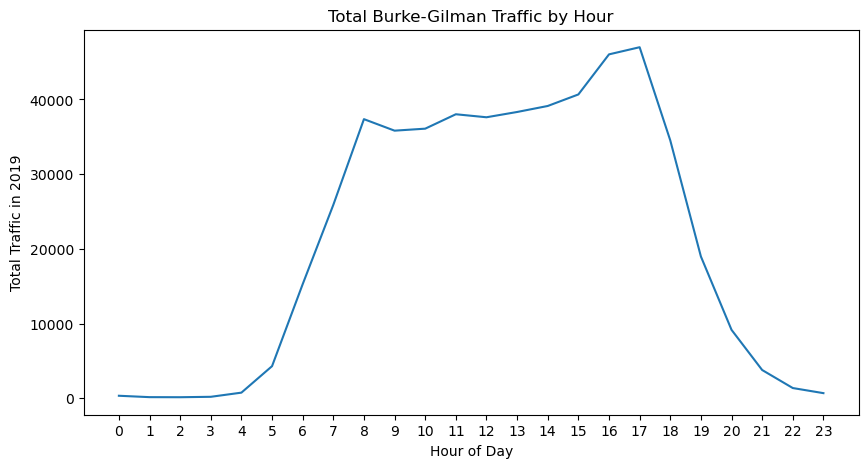

In [7]:
# Your code for Q1 (or put a Google Sheets link in your written answer below)
df["total_traffic"] = df["bikes"] + df["peds"]

traffic_by_hour = df.groupby("hour")["total_traffic"].sum()

print(traffic_by_hour)
print("Busiest hour:", traffic_by_hour.idxmax())
print("Quietest hour:", traffic_by_hour.idxmin())

traffic_by_hour.plot(figsize=(10, 5))
plt.title("Total Burke-Gilman Traffic by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Total Traffic in 2019")
plt.xticks(range(24))
plt.show()

**Your Q1 answer:**

*I defined “busiest” as the single hour with the highest combined bicycle and pedestrian traffic, since this gives a simple and reliable measure of total trail use. The busiest hour is around 5 PM, while the quietest is around 2 AM. The evening peak suggests that the trail is heavily used when people are finishing work or other daytime activities, while overnight use is very low.*

**Q2. Do cyclists and pedestrians use the trail at different times of day?**
Compare their hourly patterns. If they differ, what might explain it?

      bikes   peds
hour              
0       245     98
1        99     58
2       103     44
3       179     24
4       640    120
5      3375    929
6     11413   3862
7     19422   6472
8     24499  12870
9     21565  14263
10    22624  13471
11    26064  11960
12    26678  10943
13    28166  10162
14    29157   9975
15    30443  10232
16    34648  11393
17    37291   9706
18    26761   7767
19    14101   4886
20     6374   2793
21     2696   1093
22      969    407
23      480    212


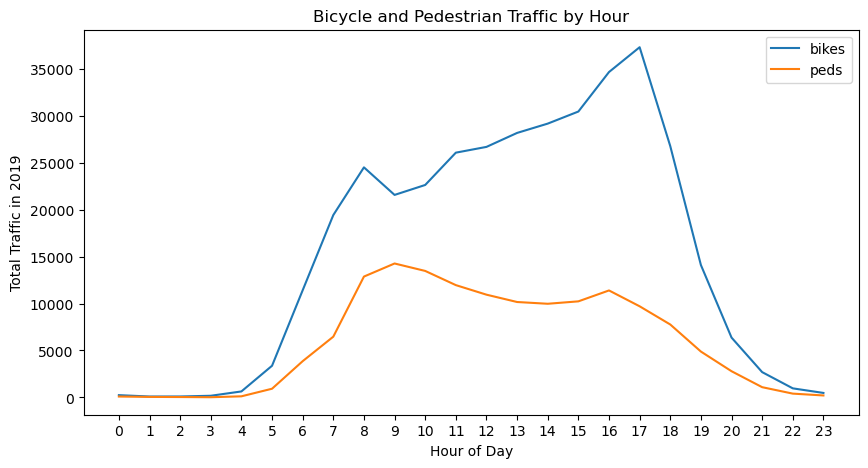

In [8]:
# Your code for Q2
bike_ped_by_hour = df.groupby("hour")[["bikes", "peds"]].sum()

print(bike_ped_by_hour)

bike_ped_by_hour.plot(figsize=(10, 5))
plt.title("Bicycle and Pedestrian Traffic by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Total Traffic in 2019")
plt.xticks(range(24))
plt.show()

**Your Q2 answer:**

*Cyclists and pedestrians show different daily patterns. Bicycle traffic shows clear morning and evening peaks, especially around 5 PM, while pedestrian traffic is more spread throughout the daytime and peaks around the morning. This may imply that cycling is more connected to regular travel such as commuting, while pedestrian use is more average and show less pattern.*

**Q3. Commuting or recreation?**
Is there evidence people use the Burke-Gilman to *commute*, not just for fun? Compare **weekdays vs. weekends** (we made a `weekday` column for you), and maybe morning vs. evening. Define what a "commuting pattern" would look like in the data, then say whether you see it.

*Hint: `df.groupby("weekday")[["bikes","peds"]].sum()` gets you started. Weekends and weekdays will look different if commuting is real.*

day_type     Weekday     Weekend
hour                            
0           0.596154    0.865385
1           0.195402    0.461538
2           0.310345    0.211538
3           0.544061    0.355769
4           2.072797    0.951923
5          11.540230    3.490385
6          39.620690   10.307692
7          63.835249   26.548077
8          71.509579   56.105769
9          51.172414   78.932692
10         42.720307  110.326923
11         45.153257  137.298077
12         45.360153  142.682692
13         49.954023  145.461538
14         54.877395  142.634615
15         63.226054  134.048077
16         88.662835  110.644231
17        111.295019   79.259615
18         83.789272   47.038462
19         42.697318   28.432692
20         18.885057   13.894231
21          8.237548    5.250000
22          2.720307    2.490385
23          1.329502    1.278846


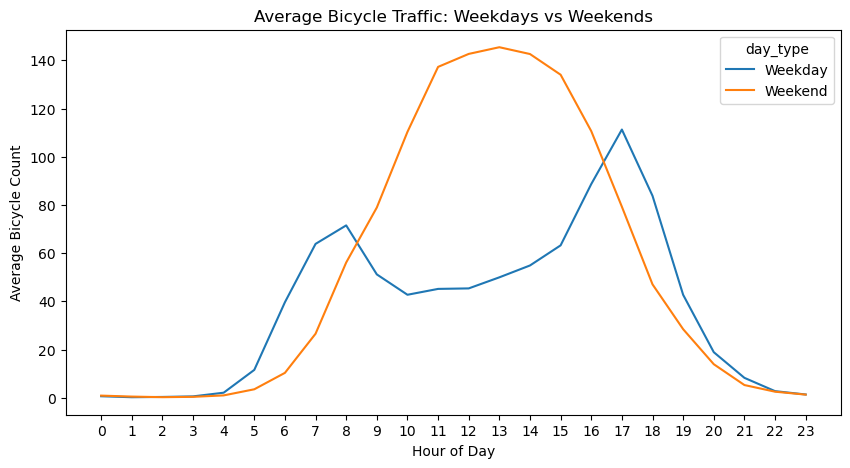

In [9]:
# Your code for Q3
df["day_type"] = df["weekday"].apply(
    lambda x: "Weekend" if x in ["Saturday", "Sunday"] else "Weekday"
)

bike_day_type = df.groupby(["hour", "day_type"])["bikes"].mean().unstack()

print(bike_day_type)

bike_day_type.plot(figsize=(10, 5))
plt.title("Average Bicycle Traffic: Weekdays vs Weekends")
plt.xlabel("Hour of Day")
plt.ylabel("Average Bicycle Count")
plt.xticks(range(24))
plt.show()

**Your Q3 answer:**

*I defined a commuting pattern as stronger weekday traffic during the morning(around 7am) and evening(5pm). From the data, the weekday bicycle pattern shows clear morning and evening peaks, which provides evidence that at least some people use the Burke-Gilman Trail for commuting. Weekend use is still substantial, looks more like a normal distribution, so the trail also appears to have a recreational role as well.*

**Q4. Direction and flow.**
The counter records **north vs. south** separately. Are mornings mostly one direction and evenings the other? What would that tell you about who's using the trail and where they're heading?

      bike_north  bike_south
hour                        
0             57         188
1             30          69
2             18          85
3             77         102
4            474         166
5           2399         976
6           7825        3588
7          13207        6215
8          16379        8120
9          11410       10155
10         10517       12107
11         12097       13967
12         12782       13896
13         12944       15222
14         13383       15774
15         13851       16592
16         13858       20790
17         12569       24722
18          9285       17476
19          5986        8115
20          3024        3350
21          1360        1336
22           405         564
23           154         326


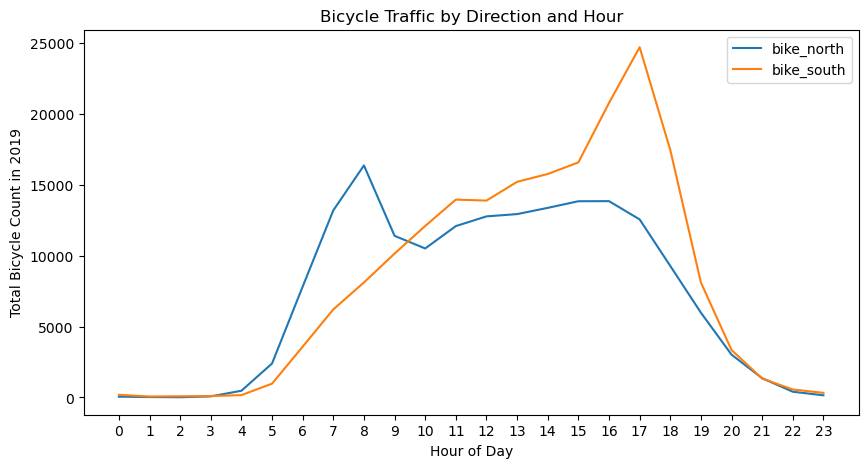

Morning (6–9 AM):
bike_north    48821
bike_south    28078
dtype: int64

Evening (4–7 PM):
bike_north    41698
bike_south    71103
dtype: int64


In [10]:
# Your code for Q4
bike_direction = df.groupby("hour")[["bike_north", "bike_south"]].sum()

print(bike_direction)

bike_direction.plot(figsize=(10, 5))
plt.title("Bicycle Traffic by Direction and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Total Bicycle Count in 2019")
plt.xticks(range(24))
plt.show()

morning = df[df["hour"].between(6, 9)][["bike_north", "bike_south"]].sum()
evening = df[df["hour"].between(16, 19)][["bike_north", "bike_south"]].sum()

print("Morning (6–9 AM):")
print(morning)

print("\nEvening (4–7 PM):")
print(evening)

**Your Q4 answer:**

*The direction of bicycle traffic changes noticeably during the day. Northbound traffic is much stronger in the morning, while southbound traffic becomes much stronger in the evening. This directional reversal is consistent with commuting or other repeated daily trips, where people travel one direction earlier in the day and return in the opposite direction later.*

## Part 3 — Make it reproducible

Good data work can be picked up and re-run by someone else. Two short deliverables:

**1. A `README.md`** in your `A1` folder. Use this template:

```
# A1 — Working with Open Data

**Dataset:** Burke-Gilman Trail counter north of NE 70th St
**Source:** https://data.seattle.gov/Transportation/.../2z5v-ecg8  (pulled YYYY-MM-DD)
**License / terms of use:** <find it on the dataset's page and note it here>

## Questions I asked
- ...

## How to re-run
Open `A1.ipynb` and run all cells (needs `requests`, `pandas`, `matplotlib`).
```

**2. A `LICENSE`** — keep the license file in this folder, and in your README **note the dataset's own license or terms of use** (open datasets almost always have one; find it on the dataset's page). Using open data responsibly means knowing what you're allowed to do with it — that's part of the assignment, not an afterthought.

### One more thing: read the data critically

In 3–4 sentences, name **one limitation or bias** in this dataset and how it could mislead someone who trusted it uncritically.

*(A sensor counts bodies, not intentions. It's one location on a long trail. Some hours may be missing when the counter was offline. A tandem bike counts once. What else?)* This is a warm-up for A2, where finding bias in data is the whole assignment.

**Your answer:**

*One limitation is that this counter measures traffic at only one location on the Burke-Gilman Trail. People may use other sections of the trail very differently, so these results should not automatically be generalized to the entire trail. The sensor also records crossings rather than individual people or their reasons for traveling, so a traffic pattern that looks like commuting does not prove that every person counted was commuting.*

## Optional — going further

If you want to push further (not required for full credit):
- Which **day of the week** is busiest? Is it the same for bikes and pedestrians?
- Has the trail gotten **busier over time**? (the data goes back to 2014 — change the year in the query)
- Do fewer people ride when it's **cold or wet**? (join with a Seattle [weather dataset](https://data.seattle.gov/))
- Compare with another counter — the [Fremont Bridge](https://data.seattle.gov/Transportation/Fremont-Bridge-Bicycle-Counter/65db-xm6k) or the [MTS Trail](https://data.seattle.gov/Transportation/MTS-Trail-west-of-I-90-Bridge-Bicycle-and-Pedestri/u38e-ybnc).

## A note on using AI

You may use an LLM (ChatGPT, Claude, …) to help you write code or make a plot. Treat it as a **tool you supervise, not an author you trust**:
- paste the **prompt** you used into a Markdown cell,
- **run** the output and check it against what you expected,
- note **what you changed and why**.

Here, AI is your assistant. In **A3** it becomes your subject of study. Code that runs but that you can't explain won't earn credit — the point is that *you* can ask a question of data and defend the answer.

### My use of AI
I used ChatGPT as a coding assistant while completing the work in Part 2. Some of the prompts I used included:

- "How to write the code to find the busiest and quietest hour using total bike and pedestrian traffic."
- "How can I compare bicycle and pedestrian traffic by hour and plot the result?"
- "How can I compare northbound and southbound bicycle traffic in the morning and evening?"
- "Explain what this traffic pattern might mean without making claims that the dataset cannot prove."

I learned and used the suggested code in my work and ran it on the provided Burke-Gilman dataset to check the numerical outputs and plots.